# Finance quantitative : risque, backtesting et optimisation de portefeuille

**Question.** Sur un univers de huit grandes valeurs technologiques (Apple, Microsoft, Nvidia, Alphabet, Meta, SAP, TSMC, Netflix), quelle méthode de construction de portefeuille offre le meilleur compromis entre rendement et risque, une fois testée honnêtement, hors échantillon et avec des frais ?

**Données.** Cours de clôture journaliers ajustés des divisions d'actions, de janvier 2019 à novembre 2026 (fichiers dans `data/raw`).

**Plan.**
1. Rendements, volatilité et corrélations
2. Mesures de risque : VaR historique, VaR gaussienne, CVaR, drawdown
3. Validation de la VaR : est ce qu'elle est dépassée aussi souvent que prévu ?
4. Frontière efficiente et portefeuilles optimisés
5. Backtest hors échantillon de cinq stratégies, avec frais de transaction
6. Base SQL et tableau de bord

In [1]:
import sys, sqlite3
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, str(Path('..') / 'src'))
import quant as q
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
NOMS = {'AAPL': 'Apple', 'MSFT': 'Microsoft', 'NVDA': 'Nvidia', 'GOOG': 'Alphabet', 'META': 'Meta',
        'SAP': 'SAP', 'TSM': 'TSMC', 'NFLX': 'Netflix'}
prix = q.load_prices('../data/raw', list(NOMS)).rename(columns=NOMS)
r = q.returns(prix)
print(f"{len(prix)} séances, du {prix.index.min():%d/%m/%Y} au {prix.index.max():%d/%m/%Y}")
prix.tail()

1984 séances, du 02/01/2019 au 20/11/2026


,Apple,Microsoft,Nvidia,Alphabet,Meta,SAP,TSMC,Netflix
date,,,,,,,,
2026-11-16,352.780,517.990,156.140,281.260,626.410,233.830,373.450,60.750
2026-11-17,351.910,506.240,155.460,277.600,618.870,222.510,359.690,59.680
2026-11-18,352.450,508.290,150.960,279.200,616.380,210.760,362.620,59.820
2026-11-19,349.210,498.300,145.980,271.020,596.220,203.230,352.090,58.460
2026-11-20,342.560,484.520,125.530,264.000,560.840,198.930,318.710,56.730


## 1. Rendements, volatilité et corrélations

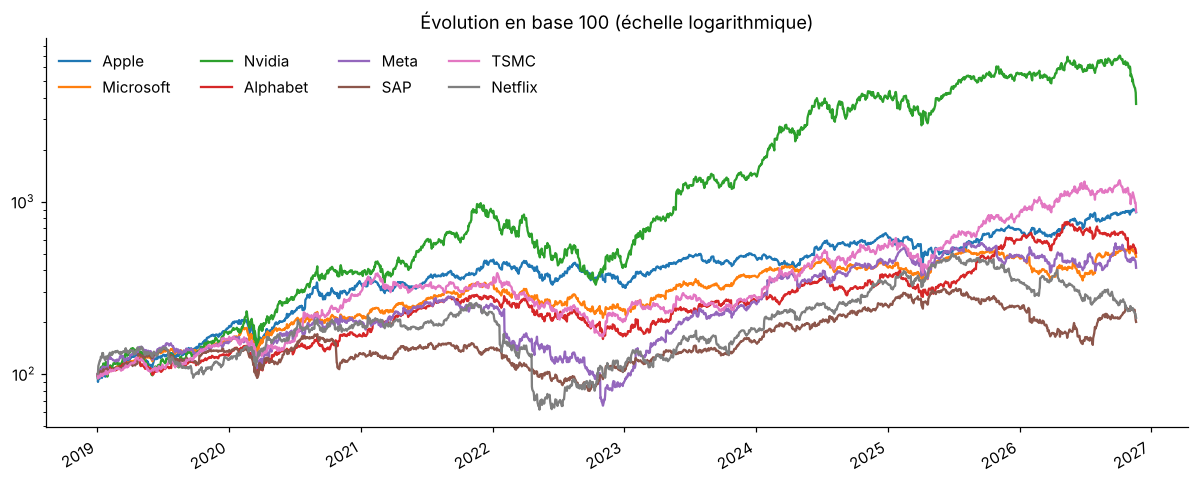

In [2]:
base = 100 * prix / prix.iloc[0]
ax = base.plot(figsize=(11, 4.5), logy=True, title='Évolution en base 100 (échelle logarithmique)')
ax.set_xlabel(''); ax.legend(ncol=4, frameon=False); plt.tight_layout(); plt.show()

In [3]:
stats = q.summary(r)
stats.sort_values('Sharpe', ascending=False)

,Rendement annualisé,Volatilité annualisée,Sharpe,Sortino,Drawdown max,VaR 95 % historique,CVaR 95 %
Nvidia,0.582,0.506,1.109,1.682,-0.664,0.046,0.068
Apple,0.316,0.305,0.969,1.438,-0.334,0.029,0.044
TSMC,0.317,0.382,0.778,1.168,-0.571,0.035,0.051
Microsoft,0.220,0.293,0.684,1.020,-0.376,0.027,0.040
Alphabet,0.228,0.315,0.661,0.964,-0.446,0.030,0.045
Meta,0.198,0.421,0.422,0.617,-0.767,0.038,0.058
SAP,0.092,0.311,0.233,0.327,-0.532,0.028,0.044
Netflix,0.100,0.420,0.191,0.271,-0.759,0.036,0.058


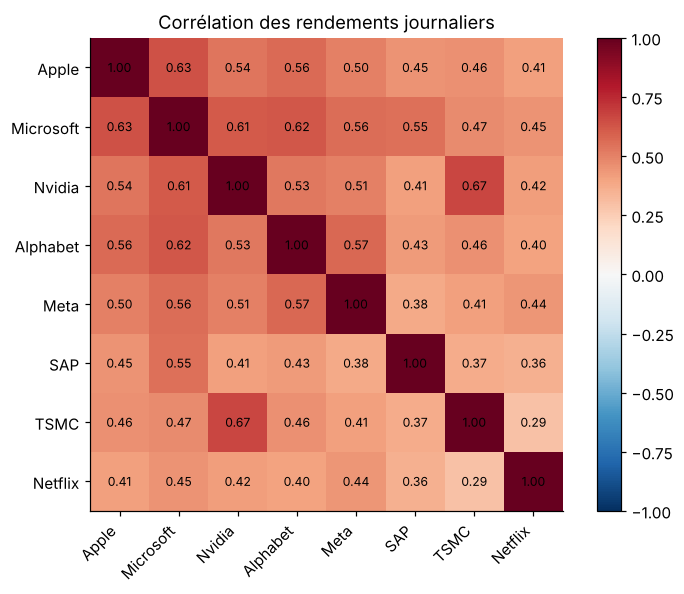

In [4]:
fig, ax = plt.subplots(figsize=(7, 5.5))
corr = r.corr()
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
plt.colorbar(im, fraction=.046); ax.set_title('Corrélation des rendements journaliers'); plt.tight_layout(); plt.show()

Les corrélations sont toutes positives et souvent supérieures à 0,5 : ces actions réagissent aux mêmes chocs (taux d'intérêt, appétit pour la tech). La diversification existe, mais elle est limitée dans un univers aussi concentré.

## 2. Mesures de risque

* **VaR historique 95 %** : la perte journalière qui n'est dépassée qu'une séance sur vingt, lue directement dans l'historique.
* **VaR gaussienne** : même idée, en supposant des rendements normaux.
* **CVaR (expected shortfall)** : la perte moyenne les jours où la VaR est dépassée. Elle dit à quel point les mauvais jours sont mauvais.

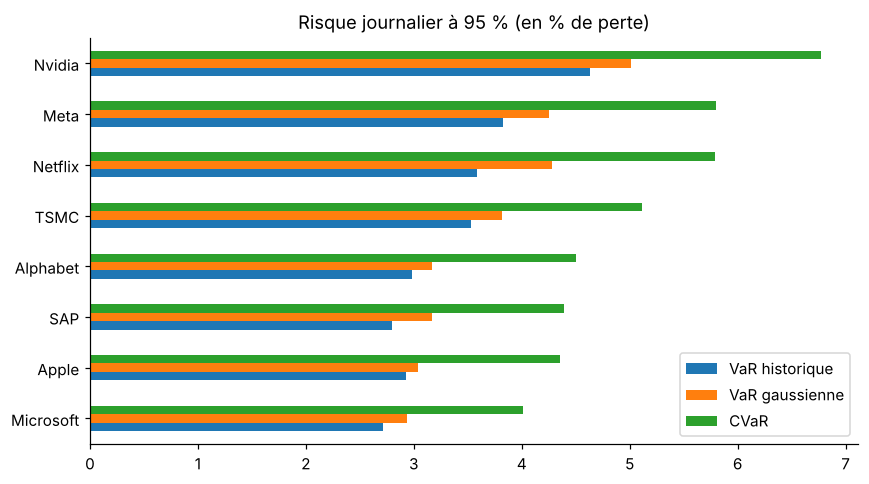

,VaR historique,VaR gaussienne,CVaR
Apple,2.920,3.040,4.360
Microsoft,2.710,2.940,4.010
Nvidia,4.640,5.010,6.780
Alphabet,2.980,3.170,4.500
Meta,3.830,4.260,5.800
SAP,2.800,3.170,4.390
TSMC,3.530,3.810,5.120
Netflix,3.580,4.280,5.790


In [5]:
risque = pd.DataFrame({'VaR historique': q.var_historique(r), 'VaR gaussienne': q.var_parametrique(r),
                       'CVaR': q.cvar(r)}, index=r.columns) * 100
risque.sort_values('CVaR').plot.barh(figsize=(8, 4.5), title='Risque journalier à 95 % (en % de perte)')
plt.tight_layout(); plt.show()
(risque).round(2)

Pour presque toutes les actions, la CVaR dépasse nettement la VaR : les pertes extrêmes sont plus lourdes que ce que suggère la loi normale (queues épaisses). C'est la raison pour laquelle on ne se contente pas de la VaR gaussienne.

## 3. Validation de la VaR (backtest de Kupiec)

On recalcule chaque jour une VaR historique à 95 % sur les 250 séances précédentes, pour un portefeuille équipondéré, puis on compte les dépassements. Si la VaR est bien calibrée, elle doit être dépassée environ 5 % du temps. Le test de Kupiec vérifie statistiquement cet écart.

105 dépassements sur 1733 jours, soit 6.06% (attendu 5 %)
Statistique de Kupiec 3.84, p valeur 0.050


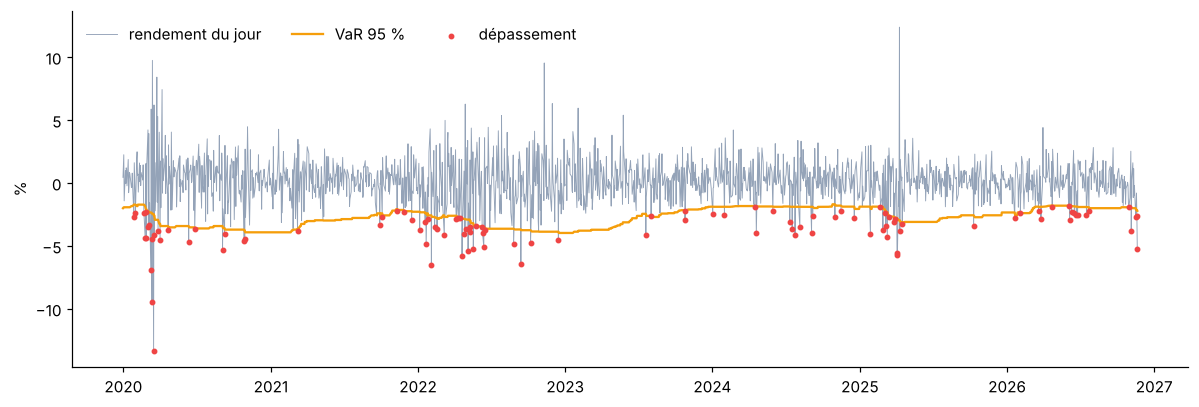

In [6]:
from scipy.stats import chi2
pf = r.mean(axis=1)
var_glissante = -pf.rolling(250).quantile(0.05).shift(1)
ok = var_glissante.notna()
depassements = (pf[ok] < -var_glissante[ok])
n, x = ok.sum(), depassements.sum()
p_hat, p0 = x / n, 0.05
lr = -2 * ((n - x) * np.log(1 - p0) + x * np.log(p0) - (n - x) * np.log(1 - p_hat) - x * np.log(p_hat))
print(f"{x} dépassements sur {n} jours, soit {p_hat:.2%} (attendu 5 %)")
print(f"Statistique de Kupiec {lr:.2f}, p valeur {1 - chi2.cdf(lr, 1):.3f}")
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(pf[ok].index, pf[ok] * 100, lw=.6, color='#94a3b8', label='rendement du jour')
ax.plot(var_glissante[ok].index, -var_glissante[ok] * 100, color='#f59e0b', label='VaR 95 %')
ax.scatter(pf[ok][depassements].index, pf[ok][depassements] * 100, s=8, color='#ef4444', label='dépassement', zorder=3)
ax.set_ylabel('%'); ax.legend(frameon=False, ncol=3); plt.tight_layout(); plt.show()

La VaR est dépassée un peu plus souvent que prévu (environ 6 % des jours contre 5 %), et le test de Kupiec est juste à la limite du rejet. Concrètement, la VaR historique sur un an glissant **sous estime légèrement** le risque, surtout juste après un choc comme mars 2020, quand la fenêtre ne contient pas encore de journées aussi violentes.

## 4. Frontière efficiente

On simule 4 000 portefeuilles aléatoires et on place trois portefeuilles optimisés : variance minimale, Sharpe maximal et parité de risque. Les poids sont limités à 35 % par action pour éviter les portefeuilles trop concentrés.

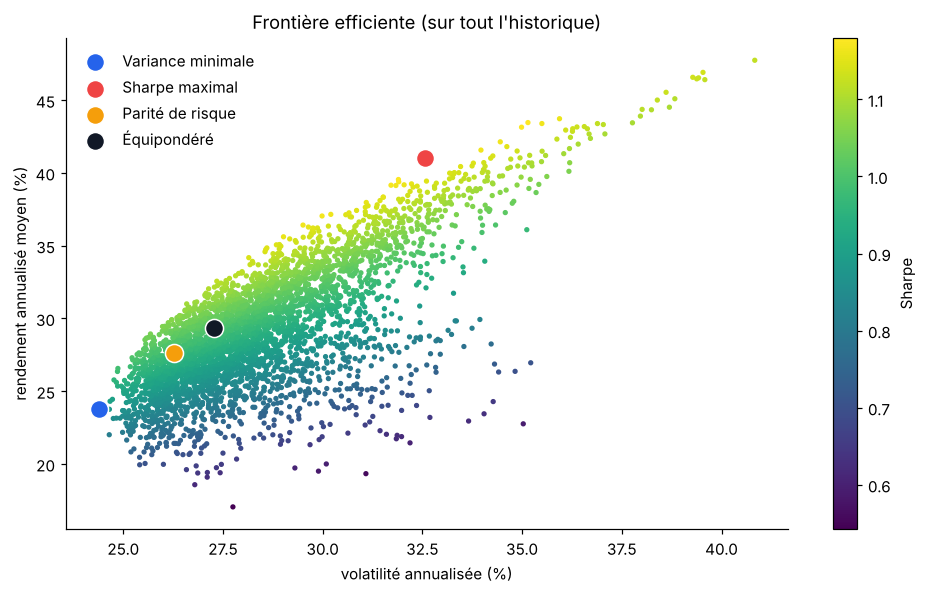

,Variance minimale,Sharpe maximal,Parité de risque,Équipondéré
Apple,20.500,35.000,14.100,12.500
Microsoft,17.600,0.000,13.800,12.500
Nvidia,0.000,35.000,8.200,12.500
Alphabet,17.800,12.800,13.700,12.500
Meta,0.000,0.000,10.500,12.500
SAP,27.800,0.000,15.400,12.500
TSMC,9.500,17.200,12.400,12.500
Netflix,6.800,0.000,12.000,12.500


In [7]:
front = q.efficient_frontier(r)
opt = {'Variance minimale': q.min_variance(r), 'Sharpe maximal': q.max_sharpe(r),
       'Parité de risque': q.risk_parity(r), 'Équipondéré': q.equal_weight(r)}
fig, ax = plt.subplots(figsize=(9, 5.5))
sc = ax.scatter(front.volatilite * 100, front.rendement * 100, c=front.sharpe, cmap='viridis', s=6)
plt.colorbar(sc, label='Sharpe')
mu, cov = r.mean() * 252, r.cov() * 252
for (nom, w), c in zip(opt.items(), ['#2563eb', '#ef4444', '#f59e0b', '#111827']):
    ax.scatter(np.sqrt(w @ cov @ w) * 100, (w @ mu) * 100, s=140, color=c, edgecolor='white', label=nom, zorder=3)
ax.set(xlabel='volatilité annualisée (%)', ylabel='rendement annualisé moyen (%)', title='Frontière efficiente (sur tout l\'historique)')
ax.legend(frameon=False); plt.tight_layout(); plt.show()
pd.DataFrame(opt).mul(100).round(1)

Attention : ces poids sont calculés avec toute la période, donc en connaissant l'avenir. Ils montrent la forme du problème, pas une performance atteignable. La section suivante corrige ce biais.

## 5. Backtest hors échantillon

Règles du backtest :
* à la fin de chaque mois, les poids sont recalculés avec **uniquement les 252 séances précédentes** ;
* les poids sont appliqués le mois suivant, et dérivent avec les prix ;
* chaque rebalancement coûte 10 points de base sur le volume échangé.

Cinq stratégies sont comparées, dont un **momentum 12 moins 1 mois** qui achète les quatre actions les plus performantes sur un an, hors dernier mois.

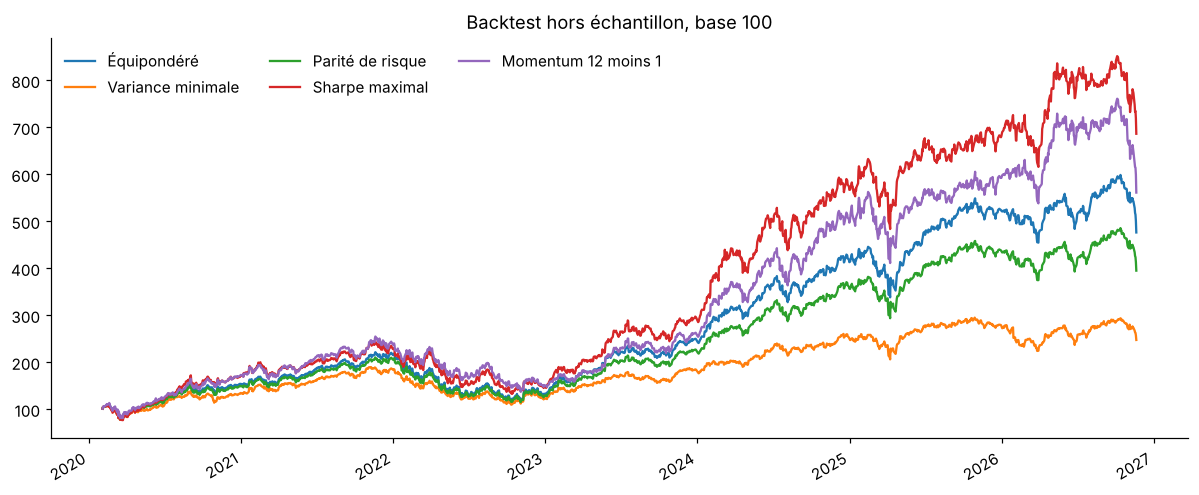

,Rendement annualisé,Volatilité annualisée,Sharpe,Sortino,Drawdown max,VaR 95 % historique,CVaR 95 %
Sharpe maximal,0.328,0.324,0.951,1.408,-0.454,0.032,0.045
Momentum 12 moins 1,0.289,0.317,0.850,1.240,-0.461,0.031,0.045
Équipondéré,0.259,0.282,0.846,1.225,-0.468,0.028,0.041
Parité de risque,0.224,0.268,0.762,1.101,-0.452,0.028,0.039
Variance minimale,0.143,0.250,0.491,0.701,-0.421,0.024,0.036


In [8]:
strategies = {'Équipondéré': q.equal_weight, 'Variance minimale': q.min_variance, 'Parité de risque': q.risk_parity,
              'Sharpe maximal': q.max_sharpe, 'Momentum 12 moins 1': q.momentum}
res = {}
for nom, fn in strategies.items():
    res[nom], _ = q.backtest(r, fn)
res = pd.DataFrame(res).dropna()
ax = (100 * (1 + res).cumprod()).plot(figsize=(11, 4.6), title='Backtest hors échantillon, base 100')
ax.set_xlabel(''); ax.legend(frameon=False, ncol=3); plt.tight_layout(); plt.show()
q.summary(res).sort_values('Sharpe', ascending=False)

In [9]:
annuel = res.groupby(res.index.year).apply(lambda x: (1 + x).prod() - 1) * 100
annuel.round(1)

,Équipondéré,Variance minimale,Parité de risque,Sharpe maximal,Momentum 12 moins 1
date,,,,,
2020,54.300,34.900,49.900,71.700,73.300
2021,39.800,36.600,37.200,32.900,37.100
2022,-38.300,-32.900,-37.300,-34.900,-36.400
2023,87.400,49.100,75.300,98.800,73.100
2024,65.900,35.900,57.700,91.900,90.000
2025,26.500,10.700,22.400,20.200,19.100
2026,-8.800,-10.800,-9.500,0.700,-5.300


**Lecture.**
* Le **Sharpe maximal** obtient le meilleur ratio de Sharpe hors échantillon (environ 0,95), porté par les semiconducteurs en 2023 et 2024, mais c'est aussi la stratégie la plus volatile.
* Le **momentum** et l'**équipondéré** font presque jeu égal (Sharpe autour de 0,85) : une règle aussi simple que « 12,5 % dans chaque action » reste une référence difficile à battre.
* La **variance minimale** a la volatilité la plus faible et le drawdown le moins profond, mais elle rate une grande partie de la hausse : son Sharpe est le plus bas.
* En 2022, aucune méthode n'échappe à une baisse de plus de 30 % : dans un univers aussi corrélé, l'optimisation ne remplace pas la diversification entre classes d'actifs.

## 6. Base SQL et tableau de bord

In [10]:
con = sqlite3.connect('../data/processed/marches.db')
pd.read_sql('''SELECT a.secteur, COUNT(DISTINCT a.ticker) AS actions,
                      ROUND(AVG(p.rendement) * 252 * 100, 1) AS rendement_moyen_annuel_pct
               FROM fait_prix p JOIN dim_actif a USING (ticker)
               WHERE p.rendement IS NOT NULL GROUP BY a.secteur ORDER BY 3 DESC''', con)

,secteur,actions,rendement_moyen_annuel_pct
0,Semiconducteurs,2,46.700
1,Matériel et logiciels,1,32.100
2,Internet et publicité,2,26.300
3,Logiciels et cloud,1,24.200
4,Médias et streaming,1,18.600
5,Logiciels d'entreprise,1,13.800


Le tableau de bord (`reports/dashboard.png` et la version interactive `reports/dashboard.html`) est généré par `src/dashboard.py` à partir de cette base. Les mêmes tables sont exportées en CSV dans `powerbi/donnees`, avec les mesures DAX dans `powerbi/mesures.dax`, pour reconstruire le rapport dans Power BI Desktop.

![Tableau de bord](../reports/dashboard.png)